In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
# Load data
df = yf.download('QQQ', start="2000-01-01", end="2020-01-01")
df.head()

/tmp/ipykernel_1318/1638271251.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('QQQ', start="2000-01-01", end="2020-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,QQQ,QQQ,QQQ,QQQ,QQQ
Date,,,,,
2000-01-03,79.927414,81.140033,76.553170,81.140033,36345200
2000-01-04,74.444275,78.872971,74.180662,77.607629,33786600
2000-01-05,72.546257,75.604166,71.070025,73.811599,42496600
2000-01-06,67.563934,74.233336,67.273960,73.284330,37134800
2000-01-07,75.920517,75.920517,69.593807,69.962865,28138200


In [ ]:
if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.get_level_values(0)

In [ ]:
df['Returns'] = df['Close'].pct_change()

In [ ]:
N = 150  # breakout lookback

# breakout levels
high_N = df['High'].rolling(N).max().shift(1)
low_N = df['Low'].rolling(N).min().shift(1)

position = 0  # 1 = long, -1 = short, 0 = flat

positions = []
entries = []
exits = []

for i in range(len(df)):
    price = df['Close'].iloc[i]

    high_ = high_N.iloc[i]
    low_ = low_N.iloc[i]

    entry = 0
    exit_ = 0

    # -----------------------
    # ENTRY RULES
    # -----------------------
    if position == 0:

        # long breakout
        if price > high_:
            position = 1
            entry = 1

        # short breakout
        elif price < low_:
            position = -1
            entry = -1

    # -----------------------
    # EXIT RULES
    # -----------------------
    elif position == 1:

        # exit long on opposite breakout
        if price < low_:
            position = 0
            exit_ = 1

    elif position == -1:

        # exit short on opposite breakout
        if price > high_:
            position = 0
            exit_ = -1

    # store results
    positions.append(position)
    entries.append(entry)
    exits.append(exit_)

# attach to dataframe
df['position'] = positions
df['entry'] = entries
df['exit'] = exits

In [ ]:
algo_returns = df['position'].shift(1) * df['Returns']

In [ ]:
# Compute cumulative return
cumulative_return = (1 + algo_returns).cumprod()
benchmark = (1 + df['Returns']).cumprod()

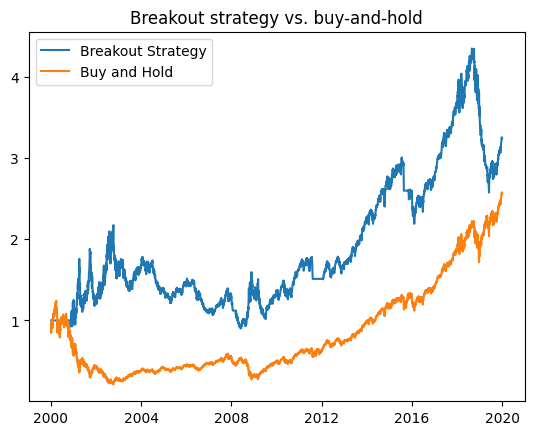

In [ ]:
# Plot cumulative return vs. buy-and-hold
plt.title("Breakout strategy vs. buy-and-hold")
plt.plot(cumulative_return, label='Breakout Strategy')
plt.plot(benchmark, label='Buy and Hold')
plt.legend(loc='upper left');

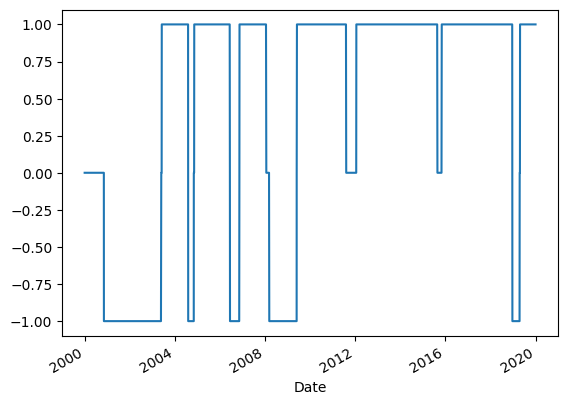

In [ ]:
df['position'].plot();